# Cardiovascular Disease Classification: Traditional Machine Learning versus Deep Learning

**Course:** Machine Learning, Summative Assignment (Model Training and Evaluation)

**Objective.** To predict the presence of cardiovascular disease from routine clinical and lifestyle measurements, and to compare scikit-learn models with Keras neural networks under a common evaluation protocol.

**Dataset.** Cardiovascular Disease dataset (Kaggle, 70,000 records, binary target `cardio`).

**Structure.** (1) Setup, (2) Data, (3) Exploration, (4) Preprocessing, (5) Evaluation tools, (6) Traditional ML, (7) Deep learning, (8) Results table, (9) Final evaluation, (10) Error analysis, (11) Artefacts, (12) Conclusions.

## 1. Setup and Reproducibility

Dependencies are installed and all random seeds are fixed (seed = 42) so that results are reproducible. Weights & Biases runs in offline mode, writing experiment logs locally.

In [1]:
!pip install -q kagglehub wandb tensorboard scikit-learn pandas matplotlib seaborn joblib

In [2]:
import os, random, json, time, warnings, shutil
os.environ["WANDB_MODE"] = "offline"          # logs saved locally in ./wandb
os.environ["WANDB_SILENT"] = "true"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
import wandb

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, average_precision_score,
                             classification_report)
from sklearn.inspection import permutation_importance
from scipy.stats import randint, uniform

SEED = 42
def set_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
set_seeds()
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Data Loading

The raw file is semicolon-delimited and contains 70,000 records. It is downloaded programmatically from Kaggle, with a manual-upload fallback. The raw file is excluded from version control and stored in the shared Drive folder.

In [3]:
RAW_PATH = "cardio_train.csv"

def get_raw_data():
    if os.path.exists(RAW_PATH):
        return RAW_PATH
    try:
        import kagglehub
        folder = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
        src = os.path.join(folder, "cardio_train.csv")
        shutil.copy(src, RAW_PATH)
    except Exception as e:
        print("Automatic download failed:", e)
        print("Download cardio_train.csv from Kaggle and upload it now.")
        from google.colab import files
        up = files.upload()
        os.rename(list(up.keys())[0], RAW_PATH)
    return RAW_PATH

raw = pd.read_csv(get_raw_data(), sep=";")
print("Raw shape:", raw.shape)
raw.head()

Using Colab cache for faster access to the 'cardiovascular-disease-dataset' dataset.
Raw shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## 3. Exploratory Data Analysis

The data are inspected for missing values, duplicates, class balance, and implausible values. Blood pressure, height, and weight contain recording errors that require cleaning (Section 4).

In [4]:
print(raw.info())
print("\nMissing values per column:\n", raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum())
print("\nClass balance (cardio):\n", raw["cardio"].value_counts(normalize=True).round(3))
raw.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB
None

Missing values per column:
 id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco  

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


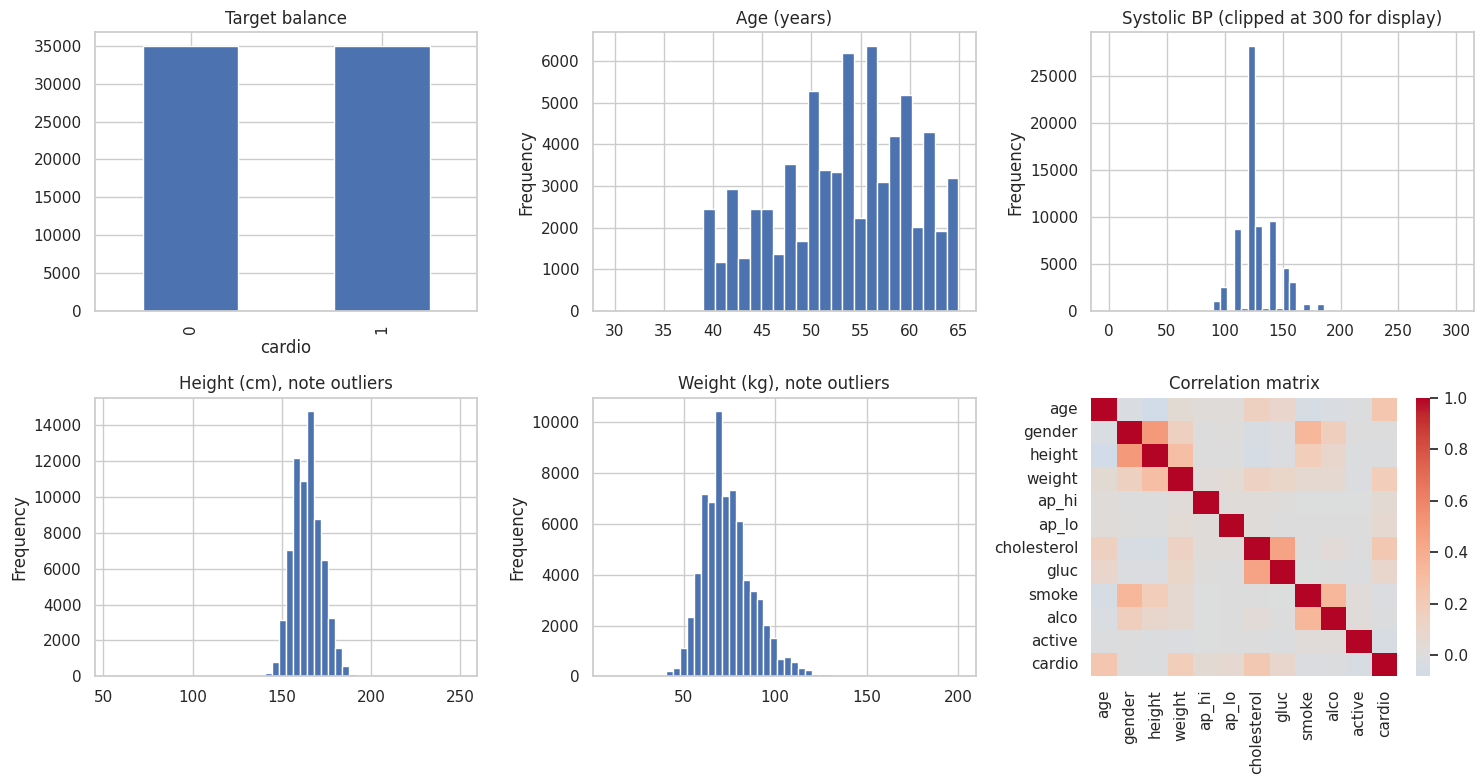

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
raw["cardio"].value_counts().plot(kind="bar", ax=axes[0,0], title="Target balance")
(raw["age"]/365.25).plot(kind="hist", bins=30, ax=axes[0,1], title="Age (years)")
raw["ap_hi"].clip(0, 300).plot(kind="hist", bins=50, ax=axes[0,2], title="Systolic BP (clipped at 300 for display)")
raw["height"].plot(kind="hist", bins=50, ax=axes[1,0], title="Height (cm), note outliers")
raw["weight"].plot(kind="hist", bins=50, ax=axes[1,1], title="Weight (kg), note outliers")
sns.heatmap(raw.drop(columns="id").corr(), cmap="coolwarm", center=0, ax=axes[1,2])
axes[1,2].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

## 4. Preprocessing and Feature Engineering

**Cleaning.** Age is converted from days to years. Duplicate rows are removed. Records are excluded when systolic pressure lies outside 70-250 mmHg, diastolic pressure outside 40-150 mmHg, diastolic exceeds systolic, height lies outside 120-220 cm, or weight lies outside 30-200 kg.

**Engineered features.** Body mass index (BMI), pulse pressure, mean arterial pressure, and a categorical blood pressure stage derived from standard clinical thresholds. Their contribution is tested in experiment E2.

**Scaling.** Features are standardised using statistics from the training split only, to prevent information leakage.

In [6]:
def clean_and_engineer(df):
    d = df.copy().drop(columns=["id"])
    n0 = len(d)
    d["age_years"] = (d["age"] / 365.25).round(1)
    d = d.drop(columns="age").drop_duplicates()
    d = d[(d.ap_hi.between(70, 250)) & (d.ap_lo.between(40, 150)) & (d.ap_hi > d.ap_lo)]
    d = d[(d.height.between(120, 220)) & (d.weight.between(30, 200))]
    d["gender"] = (d["gender"] == 2).astype(int)          # 1 = male, 0 = female
    # engineered features
    d["bmi"] = d["weight"] / (d["height"] / 100) ** 2
    d["pulse_pressure"] = d["ap_hi"] - d["ap_lo"]
    d["map"] = d["ap_lo"] + d["pulse_pressure"] / 3
    d["bp_stage"] = np.select(
        [(d.ap_hi < 120) & (d.ap_lo < 80),
         (d.ap_hi < 130) & (d.ap_lo < 80),
         (d.ap_hi < 140) & (d.ap_lo < 90)],
        [0, 1, 2], default=3)
    print(f"Rows: {n0} -> {len(d)} (removed {n0-len(d)})")
    return d.reset_index(drop=True)

df = clean_and_engineer(raw)
BASE_FEATURES = ["gender","height","weight","ap_hi","ap_lo","cholesterol","gluc","smoke","alco","active","age_years"]
ENG_FEATURES  = ["bmi","pulse_pressure","map","bp_stage"]
ALL_FEATURES  = BASE_FEATURES + ENG_FEATURES
TARGET = "cardio"
print(df[TARGET].value_counts(normalize=True).round(3))
df.describe().T

Rows: 70000 -> 67936 (removed 2064)
cardio
0    0.503
1    0.497
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
gender,67936.0,0.350403,0.477100,0.000000,0.000000,0.000000,1.000000,1.000000
height,67936.0,164.411799,7.939064,120.000000,159.000000,165.000000,170.000000,207.000000
weight,67936.0,74.189103,14.333046,30.000000,65.000000,72.000000,82.000000,200.000000
ap_hi,67936.0,126.734795,16.742562,70.000000,120.000000,120.000000,140.000000,240.000000
ap_lo,67936.0,81.316990,9.461784,40.000000,80.000000,80.000000,90.000000,150.000000
cholesterol,67936.0,1.368067,0.681085,1.000000,1.000000,1.000000,2.000000,3.000000
gluc,67936.0,1.227847,0.573785,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,67936.0,0.088819,0.284484,0.000000,0.000000,0.000000,0.000000,1.000000
alco,67936.0,0.053889,0.225800,0.000000,0.000000,0.000000,0.000000,1.000000
active,67936.0,0.802093,0.398424,0.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
# 70% train / 15% validation / 15% test, stratified so each split keeps the class balance
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df[TARGET], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=SEED)
print("Train/Val/Test:", len(train_df), len(val_df), len(test_df))

def get_xy(frame, features):
    return frame[features].values.astype("float32"), frame[TARGET].values.astype("int32")

SPLIT_DESC = "70/15/15 stratified, seed 42"

Train/Val/Test: 47555 10190 10191


### Data Partitioning

The cleaned data are divided into training (70%), validation (15%), and test (15%) sets with stratification on the target. The validation set guides model selection; the test set is used once, for the final evaluation of the two best models.

## 5. Evaluation Protocol

All experiments are scored with the same function: accuracy, precision, recall, F1-score, and ROC-AUC. Each run is appended to a results table and logged to Weights & Biases. The gap between training and validation AUC is recorded as an indicator of overfitting.

In [8]:
EXPERIMENTS = []   # every experiment appends one row here

def compute_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "accuracy":  accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred),
        "recall":    recall_score(y_true, pred),
        "f1":        f1_score(y_true, pred),
        "roc_auc":   roc_auc_score(y_true, prob),
    }

def log_experiment(exp_id, paradigm, model_name, hyperparams, features, train_m, val_m,
                   change, fit_seconds, history=None):
    row = {"id": exp_id, "paradigm": paradigm, "model": model_name,
           "hyperparameters": json.dumps(hyperparams, default=str),
           "features": features, "split": SPLIT_DESC,
           "train_auc": round(train_m["roc_auc"], 4),
           "val_accuracy": round(val_m["accuracy"], 4), "val_precision": round(val_m["precision"], 4),
           "val_recall": round(val_m["recall"], 4), "val_f1": round(val_m["f1"], 4),
           "val_auc": round(val_m["roc_auc"], 4),
           "overfit_gap_auc": round(train_m["roc_auc"] - val_m["roc_auc"], 4),
           "fit_seconds": round(fit_seconds, 1), "change_from_previous": change}
    EXPERIMENTS.append(row)
    run = wandb.init(project="cardio-summative", name=exp_id, config={**hyperparams, "model": model_name,
                     "paradigm": paradigm, "features": features}, reinit=True, mode="offline")
    if history is not None:
        for ep in range(len(history["loss"])):
            wandb.log({k: v[ep] for k, v in history.items()}, step=ep)
    wandb.log({f"val_{k}": v for k, v in val_m.items()})
    run.finish()
    print(f"{exp_id}: val AUC {val_m['roc_auc']:.4f} | acc {val_m['accuracy']:.4f} | "
          f"recall {val_m['recall']:.4f} | train-val AUC gap {train_m['roc_auc']-val_m['roc_auc']:.4f}")

## 6. Traditional Machine Learning Experiments

Logistic Regression (linear baseline), Random Forest (bagging), and Histogram Gradient Boosting (boosting) are compared. Experiments E1-E2 isolate the effect of feature engineering; E3-E4 introduce non-linear models; E5-E7 tune hyperparameters by cross-validated search on the training set only (3 folds, ROC-AUC objective).

In [9]:
Xtr_b, ytr = get_xy(train_df, BASE_FEATURES); Xva_b, yva = get_xy(val_df, BASE_FEATURES)
Xtr_a, _   = get_xy(train_df, ALL_FEATURES);  Xva_a, _   = get_xy(val_df, ALL_FEATURES)

def run_sklearn(exp_id, name, estimator, Xtr, Xva, features, hyperparams, change, scale=False):
    steps = ([("scaler", StandardScaler())] if scale else []) + [("model", estimator)]
    pipe = Pipeline(steps)
    t0 = time.time(); pipe.fit(Xtr, ytr); secs = time.time() - t0
    tr = compute_metrics(ytr, pipe.predict_proba(Xtr)[:, 1])
    va = compute_metrics(yva, pipe.predict_proba(Xva)[:, 1])
    log_experiment(exp_id, "Traditional ML", name, hyperparams, features, tr, va, change, secs)
    return pipe

# E1: Logistic Regression baseline (base features)
lr1 = run_sklearn("E1", "Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED),
                  Xtr_b, Xva_b, "base", {"C": 1.0}, "Baseline linear model", scale=True)
# E2: Logistic Regression with engineered features
lr2 = run_sklearn("E2", "Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED),
                  Xtr_a, Xva_a, "base+engineered", {"C": 1.0}, "Added BMI, pulse pressure, MAP, BP stage", scale=True)
# E3: Random Forest default on all features
rf1 = run_sklearn("E3", "Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                  Xtr_a, Xva_a, "base+engineered", {"n_estimators": 200, "max_depth": None},
                  "Switched to non-linear ensemble, default depth")
# E4: Gradient Boosting default on all features
hgb1 = run_sklearn("E4", "HistGradientBoosting", HistGradientBoostingClassifier(random_state=SEED),
                   Xtr_a, Xva_a, "base+engineered", {"learning_rate": 0.1, "max_iter": 100},
                   "Boosting instead of bagging, default settings")

E1: val AUC 0.7852 | acc 0.7213 | recall 0.6669 | train-val AUC gap 0.0076
E2: val AUC 0.7844 | acc 0.7226 | recall 0.6738 | train-val AUC gap 0.0078
E3: val AUC 0.7670 | acc 0.7081 | recall 0.7032 | train-val AUC gap 0.2330
E4: val AUC 0.7954 | acc 0.7294 | recall 0.6933 | train-val AUC gap 0.0218


In [10]:
# E5: Random Forest tuned (randomised search on the TRAIN split only)
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    {"n_estimators": randint(150, 400), "max_depth": randint(4, 14),
     "min_samples_leaf": randint(5, 60), "max_features": ["sqrt", 0.5]},
    n_iter=8, cv=3, scoring="roc_auc", random_state=SEED, n_jobs=1)
t0 = time.time(); rf_search.fit(Xtr_a, ytr); secs = time.time() - t0
rf_best = rf_search.best_estimator_
log_experiment("E5", "Traditional ML", "Random Forest (tuned)", rf_search.best_params_, "base+engineered",
               compute_metrics(ytr, rf_best.predict_proba(Xtr_a)[:, 1]),
               compute_metrics(yva, rf_best.predict_proba(Xva_a)[:, 1]),
               "Randomised search: limiting depth and leaf size to reduce overfitting", secs)

# E6: HistGradientBoosting tuned
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=SEED),
    {"learning_rate": uniform(0.02, 0.18), "max_iter": randint(100, 400),
     "max_depth": randint(3, 8), "min_samples_leaf": randint(20, 120), "l2_regularization": uniform(0, 2)},
    n_iter=10, cv=3, scoring="roc_auc", random_state=SEED, n_jobs=-1)
t0 = time.time(); hgb_search.fit(Xtr_a, ytr); secs = time.time() - t0
hgb_best = hgb_search.best_estimator_
log_experiment("E6", "Traditional ML", "HistGradientBoosting (tuned)", hgb_search.best_params_, "base+engineered",
               compute_metrics(ytr, hgb_best.predict_proba(Xtr_a)[:, 1]),
               compute_metrics(yva, hgb_best.predict_proba(Xva_a)[:, 1]),
               "Randomised search over learning rate, depth, regularisation", secs)

# E7: Logistic Regression tuned (regularisation strength)
lr_search = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))]),
                         {"model__C": [0.01, 0.1, 1, 10, 100]}, cv=3, scoring="roc_auc", n_jobs=-1)
t0 = time.time(); lr_search.fit(Xtr_a, ytr); secs = time.time() - t0
lr_best = lr_search.best_estimator_
log_experiment("E7", "Traditional ML", "Logistic Regression (tuned)", lr_search.best_params_, "base+engineered",
               compute_metrics(ytr, lr_best.predict_proba(Xtr_a)[:, 1]),
               compute_metrics(yva, lr_best.predict_proba(Xva_a)[:, 1]),
               "Grid search over regularisation strength C", secs)

E5: val AUC 0.7943 | acc 0.7296 | recall 0.6902 | train-val AUC gap 0.0260
E6: val AUC 0.7949 | acc 0.7291 | recall 0.6905 | train-val AUC gap 0.0209
E7: val AUC 0.7844 | acc 0.7228 | recall 0.6738 | train-val AUC gap 0.0078


## 7. Deep Learning Experiments

Networks are built with the Keras Sequential and Functional APIs and trained on a `tf.data` pipeline (shuffling, batching, prefetching). E8-E9 vary depth and dropout; E10 adds batch normalisation and L2 regularisation; E11 uses an excessive learning rate to examine unstable optimisation; E12 combines a lower learning rate with a learning-rate scheduler. Early stopping restores the best epoch in every run.

In [11]:
scaler = StandardScaler().fit(Xtr_a)
Xtr_s = scaler.transform(Xtr_a).astype("float32"); Xva_s = scaler.transform(Xva_a).astype("float32")
BATCH = 256

def make_ds(X, y, shuffle=False, batch=BATCH):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(Xtr_s, ytr, shuffle=True)
val_ds   = make_ds(Xva_s, yva)
N_FEAT = Xtr_s.shape[1]
METRICS = [tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Recall(name="recall")]

def seq_model(units, dropout=0.0):
    layers = [tf.keras.layers.Input(shape=(N_FEAT,))]
    for u in units:
        layers.append(tf.keras.layers.Dense(u, activation="relu"))
        if dropout: layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    return tf.keras.Sequential(layers)

def func_model(units, dropout=0.3, l2=1e-4):
    inp = tf.keras.layers.Input(shape=(N_FEAT,))
    x = inp
    for u in units:
        x = tf.keras.layers.Dense(u, kernel_regularizer=tf.keras.regularizers.l2(l2))(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inp, out)

KERAS_MODELS = {}
HISTORIES = {}

def run_keras(exp_id, name, model, lr, change, hyperparams, epochs=40, use_scheduler=False, patience=6):
    set_seeds()
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=METRICS)
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True),
           tf.keras.callbacks.TensorBoard(log_dir=f"tb_logs/{exp_id}")]
    if use_scheduler:
        cbs.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5))
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=0)
    secs = time.time() - t0
    tr = compute_metrics(ytr, model.predict(Xtr_s, batch_size=2048, verbose=0).ravel())
    va = compute_metrics(yva, model.predict(Xva_s, batch_size=2048, verbose=0).ravel())
    hp = {"lr": lr, "batch": BATCH, "epochs_run": len(hist.history["loss"]), **hyperparams}
    log_experiment(exp_id, "Deep Learning", name, hp, "base+engineered", tr, va, change, secs, hist.history)
    KERAS_MODELS[exp_id] = model; HISTORIES[exp_id] = hist.history
    return model

# E8: small Sequential network
run_keras("E8", "Sequential 64-32", seq_model([64, 32]), 1e-3,
          "Baseline neural network, no regularisation", {"units": [64, 32], "dropout": 0})
# E9: deeper network with dropout
run_keras("E9", "Sequential 128-64-32 + Dropout", seq_model([128, 64, 32], dropout=0.3), 1e-3,
          "More capacity plus dropout 0.3 to control overfitting", {"units": [128, 64, 32], "dropout": 0.3})
# E10: Functional API with BatchNorm and L2
run_keras("E10", "Functional BN+L2 128-64", func_model([128, 64], 0.3, 1e-4), 1e-3,
          "Functional API: batch normalisation and L2 weight decay", {"units": [128, 64], "dropout": 0.3, "l2": 1e-4})
# E11: too-high learning rate (instability demonstration)
run_keras("E11", "Functional BN+L2 128-64 (lr 0.05)", func_model([128, 64], 0.3, 1e-4), 5e-2,
          "Learning rate raised 50x to observe unstable optimisation", {"units": [128, 64], "dropout": 0.3, "l2": 1e-4})
# E12: lower learning rate with scheduler
run_keras("E12", "Functional BN+L2 128-64 (lr 3e-4 + scheduler)", func_model([128, 64], 0.3, 1e-4), 3e-4,
          "Lower learning rate with ReduceLROnPlateau and longer training", {"units": [128, 64], "dropout": 0.3, "l2": 1e-4, "scheduler": True},
          epochs=60, use_scheduler=True)

E8: val AUC 0.7935 | acc 0.7266 | recall 0.6902 | train-val AUC gap 0.0123
E9: val AUC 0.7937 | acc 0.7251 | recall 0.7075 | train-val AUC gap 0.0100
E10: val AUC 0.7954 | acc 0.7275 | recall 0.6757 | train-val AUC gap 0.0104
E11: val AUC 0.7921 | acc 0.7222 | recall 0.7257 | train-val AUC gap 0.0069
E12: val AUC 0.7947 | acc 0.7282 | recall 0.6923 | train-val AUC gap 0.0111


<Functional name=functional_4, built=True>

## 8. Experiment Results

The table below lists all twelve experiments with their feature set, validation metrics, the training-validation AUC gap, and the change introduced relative to the previous run. Each row is backed by an offline Weights & Biases run and, for neural networks, a TensorBoard log.

**Interpretation.** All twelve models fall within a narrow validation AUC band (0.767-0.795). The best traditional model (E4, default histogram gradient boosting) and the best network (E10, Functional API with batch normalisation and L2) tie at AUC 0.7954. Engineered features did not help logistic regression (E1: 0.7852 vs E2: 0.7844), likely because systolic pressure already carries most of the signal (Section 10.3). The default Random Forest (E3) overfitted: validation AUC was 0.767 with a train-validation gap of 0.233. Restricting depth and leaf size (E5) reduced the gap to 0.026 and raised AUC to 0.794. Tuning gradient boosting (E6: 0.7949) and logistic regression (E7: 0.7844) did not improve on the defaults, so further tuning is unlikely to yield gains.

In [12]:
results = pd.DataFrame(EXPERIMENTS)
results.to_csv("experiment_table.csv", index=False)
pd.set_option("display.max_colwidth", 80, "display.width", 250)
results[["id","paradigm","model","features","val_accuracy","val_precision","val_recall","val_f1","val_auc","overfit_gap_auc","fit_seconds","change_from_previous"]]

,id,paradigm,model,features,val_accuracy,val_precision,val_recall,val_f1,val_auc,overfit_gap_auc,fit_seconds,change_from_previous
0,E1,Traditional ML,Logistic Regression,base,0.7213,0.7458,0.6669,0.7041,0.7852,0.0076,0.3,Baseline linear model
1,E2,Traditional ML,Logistic Regression,base+engineered,0.7226,0.7441,0.6738,0.7072,0.7844,0.0078,0.4,"Added BMI, pulse pressure, MAP, BP stage"
2,E3,Traditional ML,Random Forest,base+engineered,0.7081,0.7079,0.7032,0.7055,0.7670,0.2330,21.3,"Switched to non-linear ensemble, default depth"
3,E4,Traditional ML,HistGradientBoosting,base+engineered,0.7294,0.7449,0.6933,0.7182,0.7954,0.0218,0.7,"Boosting instead of bagging, default settings"
4,E5,Traditional ML,Random Forest (tuned),base+engineered,0.7296,0.7469,0.6902,0.7174,0.7943,0.0260,170.0,Randomised search: limiting depth and leaf size to reduce overfitting
5,E6,Traditional ML,HistGradientBoosting (tuned),base+engineered,0.7291,0.7459,0.6905,0.7172,0.7949,0.0209,20.1,"Randomised search over learning rate, depth, regularisation"
6,E7,Traditional ML,Logistic Regression (tuned),base+engineered,0.7228,0.7444,0.6738,0.7073,0.7844,0.0078,1.3,Grid search over regularisation strength C
7,E8,Deep Learning,Sequential 64-32,base+engineered,0.7266,0.7420,0.6902,0.7151,0.7935,0.0123,15.2,"Baseline neural network, no regularisation"
8,E9,Deep Learning,Sequential 128-64-32 + Dropout,base+engineered,0.7251,0.7310,0.7075,0.7191,0.7937,0.0100,22.1,More capacity plus dropout 0.3 to control overfitting
9,E10,Deep Learning,Functional BN+L2 128-64,base+engineered,0.7275,0.7512,0.6757,0.7115,0.7954,0.0104,47.6,Functional API: batch normalisation and L2 weight decay


In [13]:
best_ml_id = results[results.paradigm == "Traditional ML"].sort_values("val_auc", ascending=False).iloc[0]["id"]
best_dl_id = results[results.paradigm == "Deep Learning"].sort_values("val_auc", ascending=False).iloc[0]["id"]
print("Best traditional ML experiment:", best_ml_id)
print("Best deep learning experiment:", best_dl_id)
ml_lookup = {"E1": lr1, "E2": lr2, "E3": rf1, "E4": hgb1, "E5": rf_best, "E6": hgb_best, "E7": lr_best}
best_ml = ml_lookup[best_ml_id]
best_dl = KERAS_MODELS[best_dl_id]
# E1 used only the base features; every other traditional experiment used base + engineered
best_ml_features = BASE_FEATURES if best_ml_id == "E1" else ALL_FEATURES
print("Best ML feature set:", "base" if best_ml_id == "E1" else "base+engineered")

Best traditional ML experiment: E4
Best deep learning experiment: E10
Best ML feature set: base+engineered


## 9. Final Evaluation on the Test Set

The best traditional model (E4) and the best deep learning model (E10), selected by validation AUC, are evaluated once on the held-out test set. This avoids the optimistic bias that arises from selecting and reporting models on the same data.

**Interpretation.** On the test set both models reach AUC 0.797 and accuracy 0.734, so the difference between paradigms is not practically meaningful. Gradient boosting has higher recall (0.708 vs 0.689), whereas the network has higher precision (0.755 vs 0.744).

In [14]:
Xte_ml, yte = get_xy(test_df, best_ml_features)       # features the best ML model was trained on
Xtr_ml, _   = get_xy(train_df, best_ml_features)
Xte_a, _    = get_xy(test_df, ALL_FEATURES)            # deep learning models always use all features
Xte_s = scaler.transform(Xte_a).astype("float32")
p_ml = best_ml.predict_proba(Xte_ml)[:, 1]
p_dl = best_dl.predict(Xte_s, batch_size=2048, verbose=0).ravel()

final = pd.DataFrame({f"Best ML ({best_ml_id})": compute_metrics(yte, p_ml),
                      f"Best DL ({best_dl_id})": compute_metrics(yte, p_dl)}).T.round(4)
final.to_csv("final_test_metrics.csv")
final

,accuracy,precision,recall,f1,roc_auc
Best ML (E4),0.7335,0.7438,0.7080,0.7254,0.7966
Best DL (E10),0.7341,0.7550,0.6888,0.7204,0.7966


### 9.1 Confusion Matrices

Confusion matrices at a decision threshold of 0.5 show the balance between false positives and false negatives.

**Interpretation.** Gradient boosting produced 1,480 false negatives and 1,236 false positives; the network produced 1,577 and 1,133. Both models miss more diseased patients than they falsely flag, and the network is slightly more conservative. In screening, a missed case is costlier than a false alarm, so the false negative count is the more important figure.

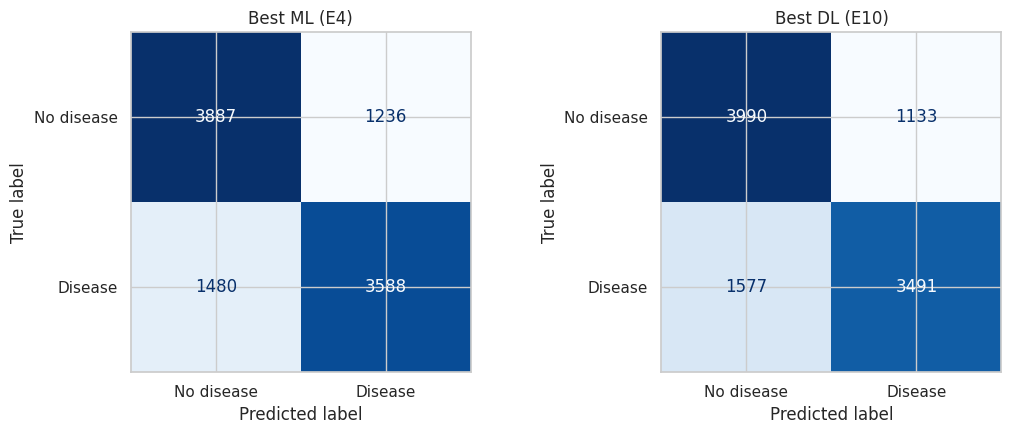

Best ML:
               precision    recall  f1-score   support

  No disease       0.72      0.76      0.74      5123
     Disease       0.74      0.71      0.73      5068

    accuracy                           0.73     10191
   macro avg       0.73      0.73      0.73     10191
weighted avg       0.73      0.73      0.73     10191

Best DL:
               precision    recall  f1-score   support

  No disease       0.72      0.78      0.75      5123
     Disease       0.75      0.69      0.72      5068

    accuracy                           0.73     10191
   macro avg       0.74      0.73      0.73     10191
weighted avg       0.74      0.73      0.73     10191



In [15]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, p) in zip(axes, [(f"Best ML ({best_ml_id})", p_ml), (f"Best DL ({best_dl_id})", p_dl)]):
    ConfusionMatrixDisplay.from_predictions(yte, (p >= 0.5).astype(int), display_labels=["No disease", "Disease"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig("fig_confusion_matrices.png", dpi=200); plt.show()

print("Best ML:\n", classification_report(yte, (p_ml >= 0.5).astype(int), target_names=["No disease", "Disease"]))
print("Best DL:\n", classification_report(yte, (p_dl >= 0.5).astype(int), target_names=["No disease", "Disease"]))

### 9.2 ROC and Precision-Recall Curves

ROC curves show discrimination across all thresholds; precision-recall curves show the trade-off for the positive class.

**Interpretation.** Both models achieve an AUC of 0.797, so their ROC curves nearly coincide. This suggests that both approaches extract the same signal from the features and that performance is limited by the data rather than by model choice.

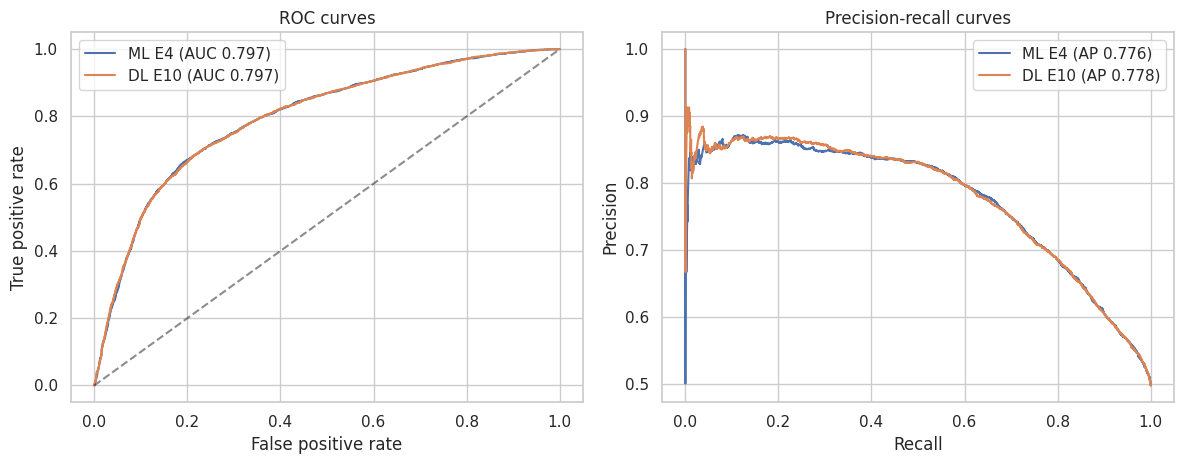

In [16]:
# ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for label, p in [(f"ML {best_ml_id}", p_ml), (f"DL {best_dl_id}", p_dl)]:
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p)
    axes[1].plot(rc, pr, label=f"{label} (AP {average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves")
for a in axes: a.legend()
plt.tight_layout(); plt.savefig("fig_roc_pr.png", dpi=200); plt.show()

### 9.3 Learning Curves

Training and validation loss per epoch diagnose overfitting and optimisation problems. A widening gap indicates high variance; two curves that plateau together at a poor score indicate high bias.

**Interpretation.** In E8, validation loss plateaus at about 0.55 while training loss keeps falling, indicating mild overfitting. E9 and E10 (dropout; batch normalisation with L2) narrow this gap. E11, with a learning rate of 0.05, shows unstable optimisation: validation loss oscillates between about 0.570 and 0.592 with a spike at epoch 7, and early stopping ends training after nine epochs. E12 (learning rate 3e-4 with a scheduler) gives the smoothest curves over about 54 epochs but no gain in AUC (0.7947 vs 0.7954 for E10).

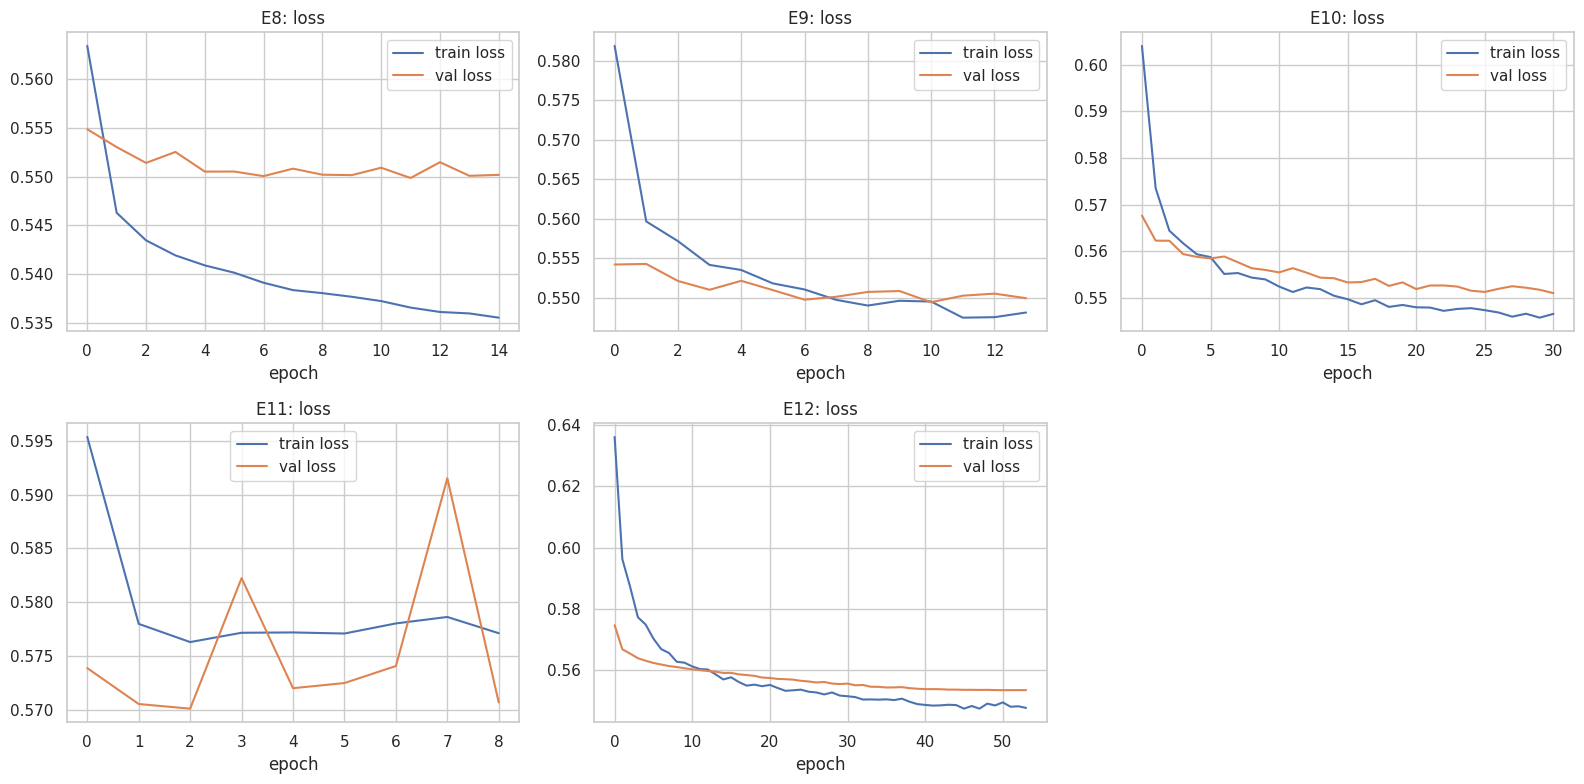

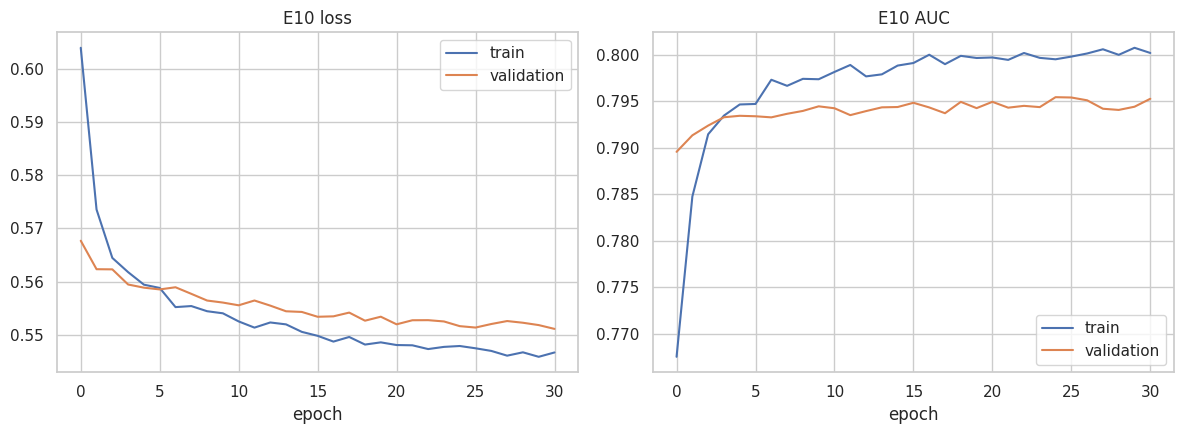

In [17]:
# Deep learning learning curves (training vs validation) for every Keras experiment
fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.ravel()
for ax, (eid, h) in zip(axes, HISTORIES.items()):
    ax.plot(h["loss"], label="train loss"); ax.plot(h["val_loss"], label="val loss")
    ax.set_title(f"{eid}: loss"); ax.set_xlabel("epoch"); ax.legend()
for ax in axes[len(HISTORIES):]: ax.axis("off")
plt.tight_layout(); plt.savefig("fig_dl_learning_curves_loss.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
h = HISTORIES[best_dl_id]
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation"); axes[0].set(title=f"{best_dl_id} loss", xlabel="epoch"); axes[0].legend()
axes[1].plot(h["auc"], label="train"); axes[1].plot(h["val_auc"], label="validation"); axes[1].set(title=f"{best_dl_id} AUC", xlabel="epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig("fig_best_dl_curves.png", dpi=200); plt.show()

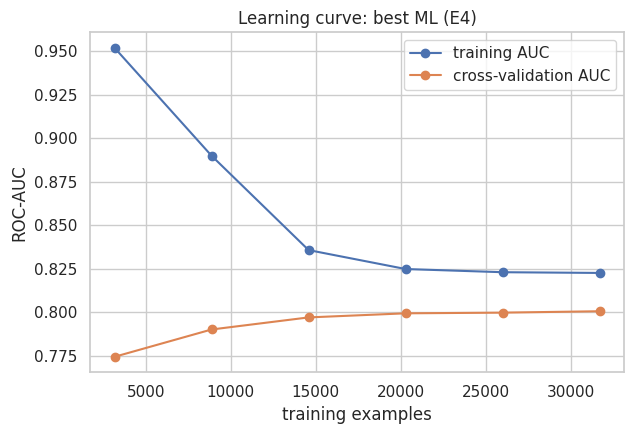

In [18]:
# Sample-size learning curve for the best traditional model (diagnoses bias vs variance)
from sklearn.base import clone
sizes, tr_scores, va_scores = learning_curve(clone(best_ml), Xtr_ml, ytr, cv=3, scoring="roc_auc",
                                             train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=SEED)
plt.figure(figsize=(6.5, 4.5))
plt.plot(sizes, tr_scores.mean(1), "o-", label="training AUC")
plt.plot(sizes, va_scores.mean(1), "o-", label="cross-validation AUC")
plt.xlabel("training examples"); plt.ylabel("ROC-AUC"); plt.title(f"Learning curve: best ML ({best_ml_id})"); plt.legend()
plt.tight_layout(); plt.savefig("fig_ml_learning_curve.png", dpi=200); plt.show()

## 10. Error Analysis

### 10.1 Characteristics of Misclassified Patients

Mean feature values are compared across true positives, true negatives, false positives, and false negatives to identify where the model fails.

**Interpretation.** False negatives resemble healthy patients: lower mean blood pressure (118/77 mmHg), younger age (52.6 years), and near-normal cholesterol (1.14). False positives resemble diseased patients: higher blood pressure (133/85 mmHg), older age (56.8 years), higher BMI (29.0), and higher cholesterol (1.56). The model fails where a patient's recorded measurements overlap with the opposite class.

In [19]:
# Where are the errors? Compare misclassified patients with correctly classified ones
err = test_df.copy()
err["prob"] = p_ml
err["pred"] = (p_ml >= 0.5).astype(int)
err["outcome"] = np.select([(err.pred == 1) & (err.cardio == 1), (err.pred == 0) & (err.cardio == 0),
                            (err.pred == 1) & (err.cardio == 0)], ["True positive", "True negative", "False positive"],
                           default="False negative")
print(err["outcome"].value_counts())
err.groupby("outcome")[["age_years", "ap_hi", "ap_lo", "bmi", "cholesterol", "gluc"]].mean().round(2)

outcome
True negative     3887
True positive     3588
False negative    1480
False positive    1236
Name: count, dtype: int64


,age_years,ap_hi,ap_lo,bmi,cholesterol,gluc
outcome,,,,,,
False negative,52.57,117.99,77.44,26.48,1.14,1.16
False positive,56.84,133.33,84.93,29.00,1.56,1.39
True negative,50.23,115.55,76.06,25.69,1.11,1.13
True positive,55.83,140.73,87.62,29.36,1.67,1.32


### 10.2 Decision Threshold

Lowering the threshold increases recall at the cost of precision.

**Interpretation.** Lowering the threshold from 0.5 to 0.3 raises recall from 0.708 to 0.878 but reduces precision from 0.744 to 0.622. A threshold of 0.4 gives the highest F1-score (0.738) with recall 0.790. For screening, where missed cases are costly, a threshold of 0.4 is a reasonable compromise.

In [20]:
# Threshold trade-off: recall matters in screening because a missed patient is costly
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    m = compute_metrics(yte, p_ml, threshold=t)
    rows.append({"threshold": t, **{k: round(v, 4) for k, v in m.items() if k != "roc_auc"}})
pd.DataFrame(rows)

,threshold,accuracy,precision,recall,f1
0,0.3,0.6736,0.6217,0.8779,0.7279
1,0.4,0.7204,0.6918,0.7897,0.7375
2,0.5,0.7335,0.7438,0.7080,0.7254
3,0.6,0.7251,0.7966,0.6004,0.6847
4,0.7,0.7114,0.8235,0.5341,0.6480


### 10.3 Feature Importance

Permutation importance measures the drop in AUC when a single feature is randomly shuffled.

**Interpretation.** Systolic blood pressure dominates (AUC drop of about 0.16), followed by age (about 0.03) and cholesterol (about 0.027). This agrees with clinical evidence that hypertension is a leading cardiovascular risk factor. Engineered features such as mean arterial pressure contribute little (about 0.003), which explains why they did not improve performance.

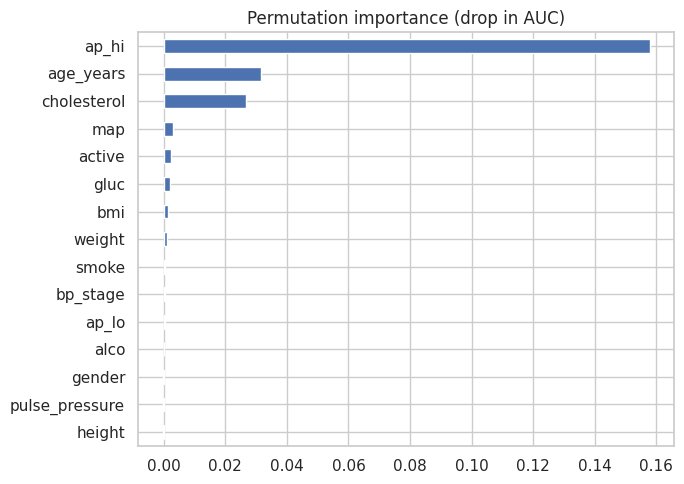

In [21]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(Xte_ml), 5000, replace=False)
pi = permutation_importance(best_ml, Xte_ml[idx], yte[idx], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=best_ml_features).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title="Permutation importance (drop in AUC)")
plt.tight_layout(); plt.savefig("fig_feature_importance.png", dpi=200); plt.show()

## 11. Saved Artefacts

The best models (`.joblib` for scikit-learn; `.h5` and `.keras` for Keras), the input scaler, and the zipped raw dataset are saved and copied to the shared Drive folder. `requirements.txt` and `.gitignore` are generated for the GitHub repository.

In [22]:
os.makedirs("artefacts", exist_ok=True)
joblib.dump(best_ml, "artefacts/best_traditional_model.joblib")
best_dl.save("artefacts/best_deep_learning_model.h5")          # HDF5 format
best_dl.save("artefacts/best_deep_learning_model.keras")       # native Keras format
joblib.dump(scaler, "artefacts/dl_input_scaler.joblib")
import zipfile
with zipfile.ZipFile("artefacts/cardio_raw_dataset.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(RAW_PATH)
print(os.listdir("artefacts"))

with open("requirements.txt", "w") as f:
    f.write("\n".join(["numpy", "pandas", "scikit-learn", "tensorflow", "wandb", "matplotlib",
                       "seaborn", "joblib", "scipy", "kagglehub", "tensorboard"]))
with open(".gitignore", "w") as f:
    f.write("cardio_train.csv\nartefacts/\nwandb/\ntb_logs/\n*.zip\n")

['dl_input_scaler.joblib', 'best_traditional_model.joblib', 'cardio_raw_dataset.zip', 'best_deep_learning_model.keras', 'best_deep_learning_model.h5']


In [26]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/cardio_summative"
    os.makedirs(dest, exist_ok=True)
    for f in os.listdir("artefacts"):
        shutil.copy(os.path.join("artefacts", f), dest)
    print("Copied to", dest, "- now set sharing to 'Anyone with the link can view'")
except Exception as e:
    print("Skipped Drive copy:", e)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to /content/drive/MyDrive/cardio_summative - now set sharing to 'Anyone with the link can view'


In [27]:
import os, glob, zipfile, shutil
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

dest = "/content/drive/MyDrive/cardio_summative"
os.makedirs(dest, exist_ok=True)

zip_name = "experiment_logs_and_results.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["wandb", "tb_logs"]:
        for root, _, files in os.walk(folder):
            for f in files:
                z.write(os.path.join(root, f))
    extra = ["experiment_table.csv", "final_test_metrics.csv"] + glob.glob("fig_*.png")
    for f in extra:
        if os.path.exists(f):
            z.write(f)
            print("added", f)

shutil.copy(zip_name, dest)
print("Copied to Drive:", os.listdir(dest))

added experiment_table.csv
added final_test_metrics.csv
added fig_dl_learning_curves_loss.png
added fig_confusion_matrices.png
added fig_roc_pr.png
added fig_feature_importance.png
added fig_ml_learning_curve.png
added fig_best_dl_curves.png
Copied to Drive: ['dl_input_scaler.joblib', 'best_traditional_model.joblib', 'cardio_raw_dataset.zip', 'best_deep_learning_model.keras', 'best_deep_learning_model.h5', 'experiment_logs_and_results.zip']


**Project links**
- GitHub repository: https://github.com/NkubaJr/cardiovascular-disease-classification
- Google Drive folder (dataset zip, model weights, logs): https://drive.google.com/drive/folders/1S1-Kac_7Cg0X0pB7FHJeNRYTV7mtAnLw?usp=sharing
- Video presentation: https://youtu.be/ty8fDyxjtko

## 12. Conclusions

**Findings.** Histogram gradient boosting (E4) and the batch-normalised Functional API network (E10) both achieved a test AUC of 0.797 and accuracy of 0.734, so neither paradigm had a meaningful advantage. The default Random Forest overfitted (train-validation AUC gap of 0.233) until its depth was restricted, and the engineered features did not improve logistic regression.

**Limitations.** Performance plateaus near 0.80 AUC. Measurements are noisy and the dataset lacks medical history, family history, and laboratory values. It comes from a single source, and 2,064 records with implausible values were removed.

**Future work.** Probability calibration, repeated cross-validation, external validation on another population, and additional clinical features.